In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


df = pd.read_csv(os.path.join("..", "datos", "credit_risk_dataset.csv"))

## Item 1: Carga e inspección inicial de los datos
Tamaño del conjunto, tipos de variables y descripción estadística.

In [3]:
print(f"Dimensiones del dataset: filas: {df.shape[0]}, columnas: {df.shape[1]}")
print(df.dtypes)
print(df.describe(include='all'))

Dimensiones del dataset: filas: 32581, columnas: 12
person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object
          person_age  person_income person_home_ownership  person_emp_length  \
count   32581.000000   3.258100e+04                 32581       31686.000000   
unique           NaN            NaN                     4                NaN   
top              NaN            NaN                  RENT                NaN   
freq             NaN            NaN                 16446                NaN   
mean       27.734600   6.607485e+04                   NaN           4.789686  

## Item 2: (codigo samuel)

                   faltantes  porcentaje
person_emp_length        895        2.75
loan_int_rate           3116        9.56

Filas con al menos un faltante: 3943
Filas con ambos faltantes: 68
Personas con edad mayor a 100 años: 5
Personas con más de 60 años de antigüedad laboral: 2

Estos valores imposibles se convirtieron en datos faltantes (NaN).
Datos faltantes por columna después de imputar:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Total de datos faltantes: 0

Primeras 5 filas del dataframe limpio:
   person_age  person_income person_home_ownership  person_emp_length  \
0          22          59000                  RENT             

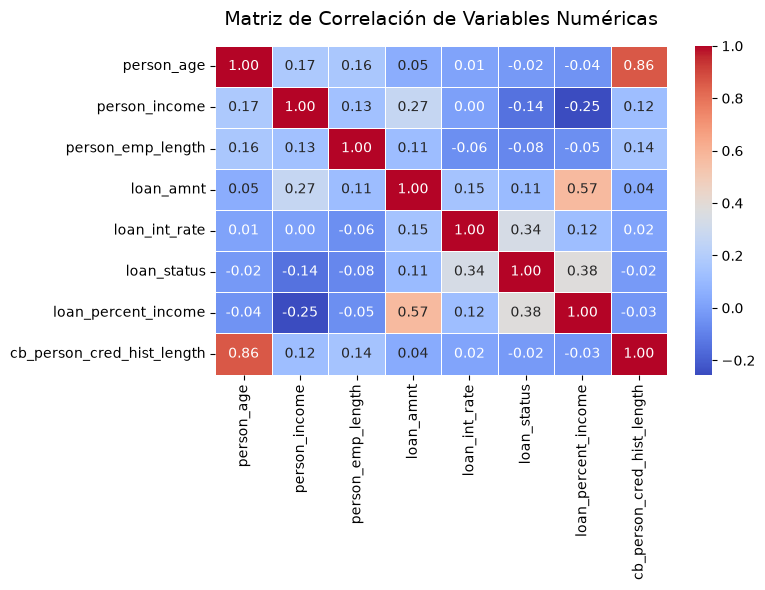

In [6]:
df_limpio = df.copy()

faltantes = pd.DataFrame({
    "faltantes": df_limpio.isna().sum(),
    "porcentaje": (df_limpio.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["faltantes"] > 0]
print(faltantes)

cols_nulos = faltantes.index.tolist()
print("\nFilas con al menos un faltante:", df_limpio.isna().any(axis=1).sum())
print("Filas con ambos faltantes:", df_limpio[cols_nulos].isna().all(axis=1).sum())

#Datos imposibles en el contexto
edades_raras = (df["person_age"] > 100).sum()
antig_rara = (df["person_emp_length"] > 60).sum()
print(f"Personas con edad mayor a 100 años: {edades_raras}")
print(f"Personas con más de 60 años de antigüedad laboral: {antig_rara}")
 
df2 = df.copy()
df2.loc[df2["person_age"] > 100, "person_age"] = np.nan
df2.loc[df2["person_emp_length"] > 60, "person_emp_length"] = np.nan
print("\nEstos valores imposibles se convirtieron en datos faltantes (NaN).")

#Imputar datos faltantes o imposibles
df_limpio["loan_int_rate"] = df_limpio["loan_int_rate"].fillna(
    df_limpio.groupby("loan_grade")["loan_int_rate"].transform("median"))

df_limpio["person_emp_length"] = df_limpio["person_emp_length"].fillna(
    df_limpio.groupby("person_home_ownership")["person_emp_length"].transform("median"))

df_limpio["person_age"] = df_limpio["person_age"].fillna(df_limpio["person_age"].median())

##Resultado despues de imputar
print("Datos faltantes por columna después de imputar:")
print(df_limpio.isna().sum())
print("\nTotal de datos faltantes:", df_limpio.isna().sum().sum())

print("\nPrimeras 5 filas del dataframe limpio:")
print(df_limpio.head())
print("\nDimensiones del dataframe limpio:", df_limpio.shape)

##Mapa de Calor
corr_matrix = df.select_dtypes(include=['number']).corr()
nulos_df = pd.DataFrame(
    {
        'Faltantes': df.isnull().sum(),
        'Porcentaje (%)': (df.isnull().mean() * 100).round(2),
    }
)
print(nulos_df[nulos_df['Faltantes'] > 0])

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title('Matriz de Correlación de Variables Numéricas', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

## Item 3: Identificacion de outliders
visualizaciones tipo boxplot

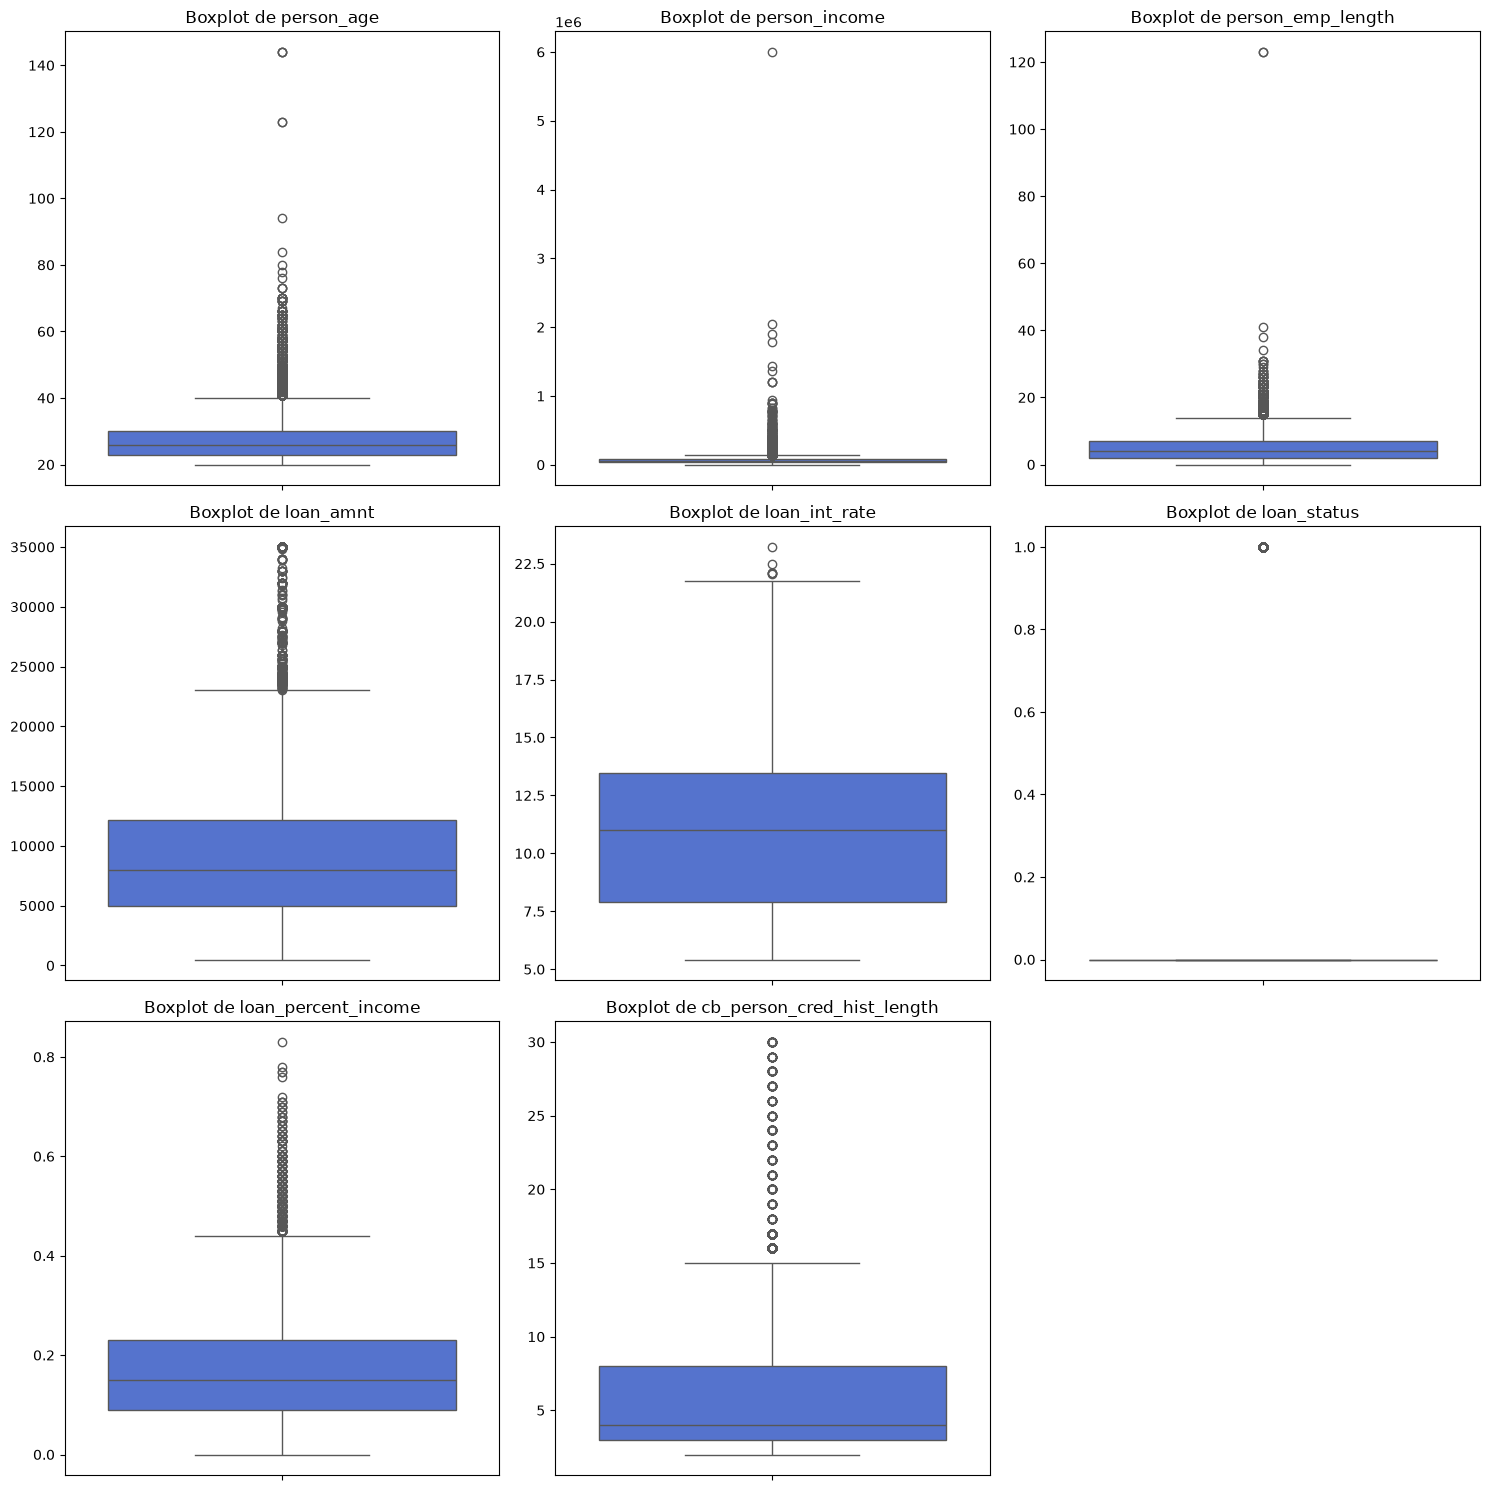

In [7]:
columnas_numericas = df_limpio.select_dtypes(include=[np.number]).columns

# 3. Calcular la disposición de la cuadrícula de gráficos (ej. 3 columnas)
num_variables = len(columnas_numericas)
num_filas = (num_variables + 2) // 3

# 4. Crear la figura y los subgráficos
fig, axes = plt.subplots(num_filas, 3, figsize=(15, 5 * num_filas))
axes = axes.flatten() # Aplanar el arreglo de ejes para iterar más fácil

# 5. Generar un boxplot para cada variable numérica
for i, col in enumerate(columnas_numericas):
    sns.boxplot(y=df_limpio[col], ax=axes[i], color='royalblue')
    axes[i].set_title(f'Boxplot de {col}')
    axes[i].set_ylabel('')

# 6. Ocultar los ejes vacíos si la cantidad de variables no es múltiplo de 3
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Ajustar el espacio y mostrar los gráficos
plt.tight_layout()
plt.show()

## Item 4: Limpieza (codigo de samuel)

In [8]:
cols_texto = df_limpio.select_dtypes(include=["object", "string"]).columns.tolist()
print("Columnas de texto:", cols_texto)

#Estandarizacion de el dataframe
antes = df_limpio[cols_texto].copy()

for col in cols_texto:
    df_limpio[col] = df_limpio[col].str.strip().str.upper()

cambios = (antes != df_limpio[cols_texto]).sum()
print("Valores modificados por columna al estandarizar:")
print(cambios)

##Analisis de los  duplicados
filas_antes = len(df_limpio)
n_duplicados = df_limpio.duplicated().sum()
print(f"Filas duplicadas exactas: {n_duplicados} "
      f"({n_duplicados / filas_antes * 100:.2f}%)")

## Eliminar duplicados
df_limpio = df_limpio.drop_duplicates(keep="first")

print(f"\nFilas antes:   {filas_antes}")
print(f"Filas después: {len(df_limpio)}")
print(f"Filas eliminadas: {filas_antes - len(df_limpio)}")
print("Duplicados restantes:", df_limpio.duplicated().sum())

print("\nLa decisión es eliminar los duplicados exactos: son registros repetidos "
      "del mismo préstamo y dejarlos sesgaría el análisis y los modelos.")
print("Dimensiones de df_limpio:", df_limpio.shape)

Columnas de texto: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
Valores modificados por columna al estandarizar:
person_home_ownership        0
loan_intent                  0
loan_grade                   0
cb_person_default_on_file    0
dtype: int64
Filas duplicadas exactas: 165 (0.51%)

Filas antes:   32581
Filas después: 32416
Filas eliminadas: 165
Duplicados restantes: 0

La decisión es eliminar los duplicados exactos: son registros repetidos del mismo préstamo y dejarlos sesgaría el análisis y los modelos.
Dimensiones de df_limpio: (32416, 12)


## Item 5: Creacion de variables
Al menos dos variables nuevas a partir de las existentes.

In [ ]:
# Variable 1: Proporción del historial crediticio respecto a la edad
# ¿Qué porcentaje de la vida de la persona abarca su historial de crédito?
df_limpio['historial_vs_edad'] = df['cb_person_cred_hist_length'] / df['person_age']
# Variable 2: Monto de interés anual estimado
# Calcula cuánto dinero representa el interés del préstamo 
# (Monto del préstamo * (Tasa de interés / 100))
df_limpio['interes_estimado'] = df['loan_amnt'] * (df['loan_int_rate'] / 100)

# Mostrar una muestra para verificar que se crearon correctamente
columnas_revision = ['person_age', 'cb_person_cred_hist_length', 'historial_vs_edad', 
                     'loan_amnt', 'loan_int_rate', 'interes_estimado']
print("Muestra de las nuevas variables:")
print(df_limpio[columnas_revision].head())

Muestra de las nuevas variables:
   person_age  cb_person_cred_hist_length  historial_vs_edad  loan_amnt  \
0          22                           3           0.136364      35000   
1          21                           2           0.095238       1000   
2          25                           3           0.120000       5500   
3          23                           2           0.086957      35000   
4          24                           4           0.166667      35000   

   loan_int_rate  interes_estimado  
0          16.02           5607.00  
1          11.14            111.40  
2          12.87            707.85  
3          15.23           5330.50  
4          14.27           4994.50  


## Item 7: Agrupación con groupby
Cinco (5) resultados relevantes, cada uno con una breve conclusión.

In [17]:
# --- Resultado 1: Perfil financiero según el estado del préstamo ---
print("1. Promedio de ingresos, monto y tasa de interés por estado del préstamo (loan_status):")
res_1 = df_limpio.groupby('loan_status')[['person_income', 'loan_amnt', 'loan_int_rate']].mean()
print(res_1)
print("\nConclusión 1: Las personas que incumplen el préstamo (1) ganan en promedio menos dinero, pero asumen tasas de interés notablemente más altas que las que sí pagan (0).\n")

# --- Resultado 2: Tasa de incumplimiento según la calificación del préstamo ---
print("2. Porcentaje de incumplimiento (default) según el grado del préstamo (loan_grade):")
res_2 = (df_limpio.groupby('loan_grade')['loan_status'].mean() * 100).sort_values(ascending=False)
print(res_2)
print("\nConclusión 2: A medida que la calificación crediticia empeora (de A hacia G), la tasa de incumplimiento se dispara, demostrando que el 'loan_grade' es un predictor altamente efectivo del riesgo.\n")

# --- Resultado 3: Riesgo según el tipo de vivienda ---
print("3. Tasa de incumplimiento según la situación de vivienda (person_home_ownership):")
res_3 = (df_limpio.groupby('person_home_ownership')['loan_status'].mean() * 100).sort_values(ascending=False)
print(res_3)
print("\nConclusión 3: Los arrendatarios (RENT) presentan un riesgo de impago considerablemente mayor frente a quienes son dueños de su casa (OWN) o pagan una hipoteca (MORTGAGE).\n")

# Resultado 4: Monto mediano del préstamo según su propósito
print("4. Monto mediano solicitado según el propósito del préstamo (loan_intent):")
res_4 = df_limpio.groupby('loan_intent')['loan_amnt'].median().sort_values(ascending=False)
print(res_4)
print("\nConclusión 4: Los préstamos destinados a consolidación de deudas o negocios exigen montos medianos más altos que aquellos solicitados para fines personales o educación.\n")

# Resultado 5: Relación préstamo/ingreso según historial de impago previo
print("5. Porcentaje del ingreso comprometido según historial de impagos (cb_person_default_on_file):")
res_5 = df_limpio.groupby('cb_person_default_on_file')['loan_percent_income'].mean() * 100
print(res_5)
print("\nConclusión 5: Los clientes que ya tienen un historial de incumplimiento previo (Y) tienden a endeudarse comprometiendo un mayor porcentaje de sus ingresos anuales frente a los que tienen el historial limpio (N).\n")

1. Promedio de ingresos, monto y tasa de interés por estado del préstamo (loan_status):
             person_income     loan_amnt  loan_int_rate
loan_status                                            
0             70849.122794   9240.155763      10.452100
1             49094.497955  10857.479898      13.049673

Conclusión 1: Las personas que incumplen el préstamo (1) ganan en promedio menos dinero, pero asumen tasas de interés notablemente más altas que las que sí pagan (0).

2. Porcentaje de incumplimiento (default) según el grado del préstamo (loan_grade):
loan_grade
G    98.437500
F    70.539419
E    64.485981
D    59.060773
C    20.751786
B    16.318475
A     9.959824
Name: loan_status, dtype: float64

Conclusión 2: A medida que la calificación crediticia empeora (de A hacia G), la tasa de incumplimiento se dispara, demostrando que el 'loan_grade' es un predictor altamente efectivo del riesgo.

3. Tasa de incumplimiento según la situación de vivienda (person_home_ownership):
person

## Item 9: Conclusiones finales

In [ ]:
print("CONCLUSIONES FINALES SOBRE EL RIESGO CREDITICIO\n")

print("1. El grado del préstamo (Loan Grade) es el principal indicador de riesgo:")
print("Se evidenció una relación drástica entre la calificación del préstamo y la probabilidad de impago. Mientras que los préstamos de categorías A y B presentan tasas de default bajas (menores al 17%), el riesgo se dispara en las peores calificaciones: los préstamos de grado F superan el 70% de incumplimiento y los de grado G alcanzan un default casi absoluto (superior al 98%).\n")

print("2. La vulnerabilidad financiera de los arrendatarios:")
print("La situación de vivienda segmenta claramente el riesgo. Los clientes que viven en arriendo (RENT) tienen una tasa de impago que supera el 31%, lo que representa más del cuádruple de riesgo frente a quienes tienen vivienda propia totalmente pagada (OWN, con un ~7.5%).\n")

print("3. La liquidez actual importa más que la edad o el historial crediticio:")
print("Las variables con mayor correlación con el impago son el porcentaje del ingreso comprometido y la tasa de interés. Por el contrario, la edad de la persona y la proporción de su vida con historial crediticio mostraron una correlación casi nula. Esto demuestra que la carga financiera mensual del solicitante pesa mucho más en el riesgo que su edad o los años que lleve en el sistema financiero.\n")



CONCLUSIONES FINALES SOBRE EL RIESGO CREDITICIO

1. El grado del préstamo (Loan Grade) es el principal indicador de riesgo:
Se evidenció una relación drástica entre la calificación del préstamo y la probabilidad de impago. Mientras que los préstamos de categorías A y B presentan tasas de default bajas (menores al 17%), el riesgo se dispara en las peores calificaciones: los préstamos de grado F superan el 70% de incumplimiento y los de grado G alcanzan un default casi absoluto (superior al 98%).

2. La vulnerabilidad financiera de los arrendatarios:
La situación de vivienda segmenta claramente el riesgo. Los clientes que viven en arriendo (RENT) tienen una tasa de impago que supera el 31%, lo que representa más del cuádruple de riesgo frente a quienes tienen vivienda propia totalmente pagada (OWN, con un ~7.5%).

3. La liquidez actual importa más que la edad o el historial crediticio:
Las variables con mayor correlación con el impago son el porcentaje del ingreso comprometido y la tasa 